<a href="https://colab.research.google.com/github/SattikBhaumik/Analyzing_Exoplanets/blob/main/CS156_Session_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Linear Regression

In [ ]:
#code pasted from ChatGPT response after providing it with the above given prompt

#Linear Regression here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score


#load the Iris dataset
def load_data():
    iris = load_iris()

    X = pd.DataFrame(iris.data, columns=iris.feature_names)
    y_species = iris.target

    return iris, X, y_species


#fit a linear regression model
def fit_linear_regression(X, test_size=0.33, random_state=101):
    #predict sepal length from the other three measurements
    X_linear = X.drop(columns="sepal length (cm)")
    y = X["sepal length (cm)"]

    X_train, X_test, y_train, y_test = train_test_split(
        X_linear, y,
        test_size=test_size,
        random_state=random_state
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    return model, X_test, y_test, predictions, rmse


##Logistic Regression

Linear Regression RMSE: 0.326
Logistic Regression Accuracy: 0.980


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


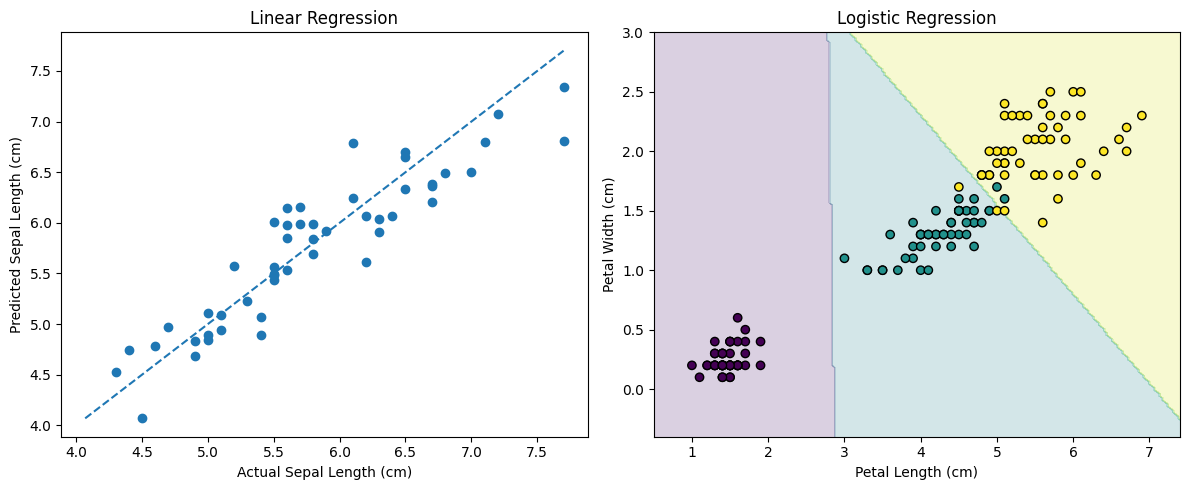

In [ ]:
#logistic regression here


#fit a logistic regression model
def fit_logistic_regression(X, y_species, test_size=0.33, random_state=101):
    #use petal length and petal width so we can visualize the classifier
    features = [
        "petal length (cm)",
        "petal width (cm)"
    ]

    X_logistic = X[features]

    X_train, X_test, y_train, y_test = train_test_split(
        X_logistic, y_species,
        test_size=test_size,
        random_state=random_state
    )

    model = LogisticRegression()
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    return model, X_logistic, y_species, accuracy


#visualize both models side-by-side
def visualize_models(
    linear_model, X_test, y_test, linear_predictions,
    logistic_model, X_logistic, y_logistic
):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    #linear regression
    ax1.scatter(y_test, linear_predictions)

    #perfect prediction line: y = x
    minimum = min(y_test.min(), linear_predictions.min())
    maximum = max(y_test.max(), linear_predictions.max())

    ax1.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--"
    )

    ax1.set_xlabel("Actual Sepal Length (cm)")
    ax1.set_ylabel("Predicted Sepal Length (cm)")
    ax1.set_title("Linear Regression")

    #logistic regression
    x_min = X_logistic.iloc[:, 0].min() - 0.5
    x_max = X_logistic.iloc[:, 0].max() + 0.5
    y_min = X_logistic.iloc[:, 1].min() - 0.5
    y_max = X_logistic.iloc[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = logistic_model.predict(grid)
    predictions = predictions.reshape(xx.shape)

    ax2.contourf(xx, yy, predictions, alpha=0.2)

    scatter = ax2.scatter(
        X_logistic.iloc[:, 0],
        X_logistic.iloc[:, 1],
        c=y_logistic,
        edgecolor="black"
    )

    ax2.set_xlabel("Petal Length (cm)")
    ax2.set_ylabel("Petal Width (cm)")
    ax2.set_title("Logistic Regression")

    plt.tight_layout()
    plt.show()


#run the pipeline
iris, X, y_species = load_data()

linear_model, X_test, y_test, linear_predictions, rmse = \
    fit_linear_regression(X)

logistic_model, X_logistic, y_logistic, accuracy = \
    fit_logistic_regression(X, y_species)

print(f"Linear Regression RMSE: {rmse:.3f}")
print(f"Logistic Regression Accuracy: {accuracy:.3f}")

visualize_models(
    linear_model,
    X_test,
    y_test,
    linear_predictions,
    logistic_model,
    X_logistic,
    y_logistic
)

##Residual plot

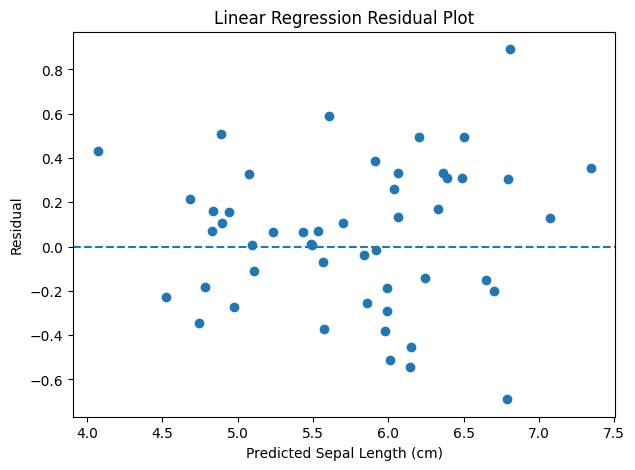

RMSE: 0.32636597428202985


In [ ]:
#code for measuring regression badness.
#code source: ChatGPT

def plot_residuals(y_test, predictions):
    residuals = y_test - predictions

    plt.figure(figsize=(7, 5))

    plt.scatter(predictions, residuals)

    # Reference line at residual = 0
    plt.axhline(y=0, linestyle="--")

    plt.xlabel("Predicted Sepal Length (cm)")
    plt.ylabel("Residual")
    plt.title("Linear Regression Residual Plot")

    plt.show()

plot_residuals(y_test, linear_predictions)
rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
print("RMSE:", rmse)

## Scratch Code

In [ ]:
#linear regression from scratch
import numpy as np
def linear_regression_scratch(x, y):
    '''
    here the function is solving
    for weight w as a transformation:
    (x^T.x)^(-1). x^T. y --> linear algerbra: CS113
    '''
    x1 = np.column_stack([np.ones(len(x), x)])
    xtx = np.dot(x1.T, x1)
    xty = np.dot(x1.T, y)
    weight = np.linalg.solve(xtx, xty)
    return weight

def linear_prediction(x, w):
    x1 = np.column_stack([np.ones(len(x), x)])
    return np.dot(x1, w)

# this code was suggested to me by claude since I was getting errors with my own code so I decided to include it here:
def sigmoid_function(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

In [ ]:
#logistic regression from scratch

#claude helped me understand what was wrong with my code. Hence, I read through the responses and rewrote my code again here:

def logistic_regression_scratch(X, y, lr=0.1, n_iters=5000):
    #claude's Main Idea of help to me:
        # NO closed form exists because p = sigmoid(Xw) is nonlinear in w
    # instead we should walk downhill on the cross-entropy loss via its gradient,
    # X^T(p - y), until w converges
    x1 = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(x1.shape[1])

    for _ in range(n_iters):
        z = np.dot(x1, w)
        p = sigmoid_function(z)
        error = p - y
        gradient = np.dot(x1.T, error) / len(y)
        w = w - lr * gradient
    return w

def logistic_prediction_scratch(X, w):
    x1 = np.column_stack([np.ones(len(X)), X])
    z = np.dot(x1, w)
    return sigmoid_function(z)